## Import libraries and set constants

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

CLINIC_CLOSE_MINUTE = 480  # 17:00 when minute 0 represents 09:00
BASE_TEMPLATE_SIZE = 30
N_CLINICIANS = 2
URGENT_WAIT_REVIEW_MIN = 30  # illustrative lab rule, not a clinical standard

## Generate synthetic appointment requests

In [2]:
def make_synthetic_requests(seed=7, n_requests=40):
    # Create fictional requests and scores available before the clinic day.
    rng = np.random.default_rng(seed)
    access_group = rng.choice(
        ["near_clinic", "far_from_clinic"],
        size=n_requests,
        p=[0.65, 0.35],
    )
    travel_minutes = np.where(
        access_group == "near_clinic",
        rng.integers(5, 31, n_requests),
        rng.integers(35, 91, n_requests),
    )
    prior_missed = rng.binomial(2, np.where(access_group == "near_clinic", 0.12, 0.22))
    raw_score = -2.8 + 0.018 * travel_minutes + 0.75 * prior_missed
    predicted_no_show = 1 / (1 + np.exp(-raw_score))

    requests = pd.DataFrame(
        {
            "request_id": [f"R{i:03d}" for i in range(n_requests)],
            "patient_id": [f"P{i:03d}" for i in range(n_requests)],
            "request_order": np.arange(1, n_requests + 1),
            "access_group": access_group,
            "travel_minutes": travel_minutes,
            "prior_missed_appointments": prior_missed,
            "predicted_no_show_probability": np.clip(predicted_no_show, 0.05, 0.60),
        }
    )
    return requests


requests = make_synthetic_requests()
requests.head()

,request_id,patient_id,request_order,access_group,travel_minutes,prior_missed_appointments,predicted_no_show_probability
0,R000,P000,1,near_clinic,18,0,0.077558
1,R001,P001,2,far_from_clinic,68,1,0.304492
2,R002,P002,3,far_from_clinic,59,0,0.149567
3,R003,P003,4,near_clinic,27,0,0.089970
4,R004,P004,5,near_clinic,9,1,0.131473


## Exercise 1: Audit appointment requests

In [3]:
print("Rows:", len(requests))
print("Unique request_id:", requests["request_id"].nunique(), "| Unique patient_id:", requests["patient_id"].nunique())
print("Missing values per column:", requests.isna().sum().sum())
display(requests.describe().round(3))

request_audit_by_group = requests.groupby("access_group").agg(
    requests=("request_id", "count"),
    mean_travel_min=("travel_minutes", "mean"),
    mean_no_show=("predicted_no_show_probability", "mean"),
    min_no_show=("predicted_no_show_probability", "min"),
    max_no_show=("predicted_no_show_probability", "max"),
).round(3)
request_audit_by_group

Rows: 40
Unique request_id: 40 | Unique patient_id: 40
Missing values per column: 0


,request_order,travel_minutes,prior_missed_appointments,predicted_no_show_probability
count,40.00,40.000,40.000,40.000
mean,20.50,29.625,0.275,0.125
std,11.69,22.575,0.452,0.068
min,1.00,6.000,0.000,0.063
25%,10.75,14.000,0.000,0.077
50%,20.50,20.500,0.000,0.094
75%,30.25,44.000,1.000,0.154
max,40.00,89.000,1.000,0.320


,requests,mean_travel_min,mean_no_show,min_no_show,max_no_show
access_group,,,,,
far_from_clinic,11,62.818,0.198,0.117,0.320
near_clinic,29,17.034,0.097,0.063,0.171


## Exercise 1: Check request data

In [4]:
assert requests["request_id"].is_unique, "request_id must be unique"
assert requests["patient_id"].is_unique, "This fixture expects one request per patient"
assert requests["predicted_no_show_probability"].between(0, 1).all()

if request_audit_by_group is None:
    print("Complete Exercise 1: create request_audit_by_group.")
else:
    display(request_audit_by_group)

,requests,mean_travel_min,mean_no_show,min_no_show,max_no_show
access_group,,,,,
far_from_clinic,11,62.818,0.198,0.117,0.320
near_clinic,29,17.034,0.097,0.063,0.171


## Build the clinic schedule

In [5]:
def build_schedule(
    request_table,
    reserve_slots=0,
    overbook_slots=0,
    score_guided_overbooking=False,
    base_template_size=BASE_TEMPLATE_SIZE,
):
    # Create a pre-opening schedule without using realized attendance.
    if reserve_slots < 0 or overbook_slots < 0:
        raise ValueError("reserve_slots and overbook_slots must be non-negative")
    regular_places = base_template_size - reserve_slots
    if regular_places <= 0:
        raise ValueError("reserve_slots leave no routine appointment places")
    if regular_places + overbook_slots > len(request_table):
        raise ValueError("Not enough appointment requests for this policy")

    template = np.repeat(np.arange(0, 450, 30), 2)
    if reserve_slots:
        # Spread nominal reserved capacity across the day instead of simply
        # removing the final appointments. Same-day arrivals still join the queue.
        reserved_positions = np.floor(
            (np.arange(reserve_slots) + 0.5) * len(template) / reserve_slots
        ).astype(int)
        regular_template = np.delete(template, reserved_positions)
    else:
        regular_template = template
    selected = request_table.sort_values("request_order").head(regular_places).copy()
    selected["scheduled_minute"] = regular_template[:regular_places]
    selected["booking_type"] = "standard"

    if overbook_slots:
        waitlist = (
            request_table.sort_values("request_order")
            .iloc[regular_places : regular_places + overbook_slots]
            .copy()
        )
        if score_guided_overbooking:
            host_slots = selected.nlargest(
                overbook_slots, "predicted_no_show_probability"
            )["scheduled_minute"].to_numpy()
        else:
            host_slots = selected.tail(overbook_slots)["scheduled_minute"].to_numpy()
        waitlist["scheduled_minute"] = host_slots
        waitlist["booking_type"] = "overbooked"
        selected = pd.concat([selected, waitlist], ignore_index=True)

    return selected.sort_values(
        ["scheduled_minute", "booking_type", "request_order"], kind="stable"
    ).reset_index(drop=True)


baseline_schedule = build_schedule(requests)
baseline_schedule[[
    "request_id",
    "patient_id",
    "scheduled_minute",
    "booking_type",
    "predicted_no_show_probability",
]].head(8)

,request_id,patient_id,scheduled_minute,booking_type,predicted_no_show_probability
0,R000,P000,0,standard,0.077558
1,R001,P001,0,standard,0.304492
2,R002,P002,30,standard,0.149567
3,R003,P003,30,standard,0.089970
4,R004,P004,60,standard,0.131473
5,R005,P005,60,standard,0.319950
6,R006,P006,90,standard,0.092961
7,R007,P007,90,standard,0.116500


## Queue engine and clinic-day simulation

In [6]:
def process_queue(arrivals, n_clinicians=N_CLINICIANS, queue_rule="fcfs"):
    # Run a non-preemptive multi-clinician queue. FCFS selects the
    # longest-waiting arrival; urgent_priority selects urgent visits first,
    # then by arrival. A consultation in progress is never interrupted.
    if queue_rule not in {"fcfs", "urgent_priority"}:
        raise ValueError("queue_rule must be 'fcfs' or 'urgent_priority'")
    if n_clinicians < 1:
        raise ValueError("n_clinicians must be at least 1")

    pending = arrivals.sort_values("arrival_minute", kind="stable").reset_index(drop=True)
    server_available = np.zeros(n_clinicians, dtype=float)
    waiting = []
    records = []
    next_arrival_index = 0
    current_time = 0.0

    while next_arrival_index < len(pending) or waiting:
        if not waiting:
            current_time = max(
                current_time,
                float(pending.loc[next_arrival_index, "arrival_minute"]),
            )

        while (
            next_arrival_index < len(pending)
            and pending.loc[next_arrival_index, "arrival_minute"] <= current_time
        ):
            waiting.append(pending.loc[next_arrival_index].to_dict())
            next_arrival_index += 1

        free_servers = np.flatnonzero(server_available <= current_time)
        while waiting and len(free_servers):
            if queue_rule == "urgent_priority":
                chosen_index = min(
                    range(len(waiting)),
                    key=lambda i: (
                        0 if waiting[i]["urgency"] == "urgent" else 1,
                        waiting[i]["arrival_minute"],
                        waiting[i]["visit_id"],
                    ),
                )
            else:
                chosen_index = min(
                    range(len(waiting)),
                    key=lambda i: (waiting[i]["arrival_minute"], waiting[i]["visit_id"]),
                )

            visit = waiting.pop(chosen_index)
            server = int(free_servers[0])
            start = current_time
            finish = start + float(visit["service_duration_min"])
            records.append(
                {
                    **visit,
                    "clinician": server + 1,
                    "service_start_minute": start,
                    "completion_minute": finish,
                    "wait_min": start - float(visit["arrival_minute"]),
                }
            )
            server_available[server] = finish
            free_servers = np.flatnonzero(server_available <= current_time)

        if waiting:
            current_time = float(server_available.min())
        elif next_arrival_index < len(pending):
            current_time = max(
                current_time,
                float(pending.loc[next_arrival_index, "arrival_minute"]),
            )

    return pd.DataFrame(records).sort_values(
        ["service_start_minute", "clinician"], kind="stable"
    ).reset_index(drop=True)


def simulate_clinic_day(
    schedule,
    seed,
    n_clinicians=N_CLINICIANS,
    queue_rule="fcfs",
    urgent_rate=4.0,
    no_show_logit_shift=0.0,
):
    # Realize attendance and demand, then process one fictional clinic day.
    # no_show_logit_shift changes actual non-attendance odds while leaving the
    # pre-opening predicted probabilities unchanged. It supports a drift test.
    # Independent streams keep urgent demand and shared patient outcomes aligned
    # when the same seed is used to compare policies of different sizes.
    streams = np.random.SeedSequence(seed).spawn(6)
    attendance_rng, arrival_rng, service_rng, urgent_count_rng, urgent_arrival_rng, urgent_service_rng = [
        np.random.default_rng(stream) for stream in streams
    ]
    regular = schedule.copy()
    predicted = regular["predicted_no_show_probability"].to_numpy()
    predicted_logit = np.log(predicted / (1 - predicted))
    actual_no_show_probability = 1 / (
        1 + np.exp(-(predicted_logit + no_show_logit_shift))
    )
    showed_up = attendance_rng.random(len(regular)) >= actual_no_show_probability

    attended = regular.loc[showed_up].copy()
    attended["visit_id"] = "V-" + attended["request_id"]
    attended["source"] = "scheduled"
    attended["urgency"] = "routine"
    attended["arrival_minute"] = np.maximum(
        0,
        attended["scheduled_minute"].to_numpy()
        + arrival_rng.normal(0, 8, len(attended)),
    )
    attended["service_duration_min"] = np.clip(
        service_rng.lognormal(np.log(24), 0.35, len(attended)), 8, 60
    )

    urgent_count = urgent_count_rng.poisson(urgent_rate)
    urgent = pd.DataFrame(
        {
            "visit_id": [f"U-{seed}-{i}" for i in range(urgent_count)],
            "request_id": pd.NA,
            "patient_id": [f"UP-{seed}-{i}" for i in range(urgent_count)],
            "request_order": pd.NA,
            "access_group": "not_recorded_for_urgent_fixture",
            "travel_minutes": np.nan,
            "prior_missed_appointments": np.nan,
            "predicted_no_show_probability": np.nan,
            "scheduled_minute": np.nan,
            "booking_type": "same_day_request",
            "source": "same_day",
            "urgency": "urgent",
            "arrival_minute": urgent_arrival_rng.uniform(0, 420, urgent_count),
            "service_duration_min": np.clip(
                urgent_service_rng.lognormal(np.log(30), 0.35, urgent_count), 10, 75
            ),
        }
    )

    arrivals = pd.concat([attended, urgent], ignore_index=True, sort=False)
    return process_queue(arrivals, n_clinicians=n_clinicians, queue_rule=queue_rule)

## Test the queue engine on a small example

In [7]:
toy_arrivals = pd.DataFrame(
    {
        "visit_id": ["P1", "P2", "P3"],
        "patient_id": ["P1", "P2", "P3"],
        "source": ["scheduled"] * 3,
        "urgency": ["routine"] * 3,
        "access_group": ["toy"] * 3,
        "arrival_minute": [0.0, 5.0, 25.0],
        "service_duration_min": [20.0, 15.0, 10.0],
    }
)
toy_result = process_queue(toy_arrivals, n_clinicians=1, queue_rule="fcfs")

assert toy_result["wait_min"].tolist() == [0.0, 15.0, 10.0]
assert toy_result["completion_minute"].tolist() == [20.0, 35.0, 45.0]
print("Deterministic FCFS check passed.")
toy_result[[
    "visit_id", "arrival_minute", "service_start_minute",
    "completion_minute", "wait_min"
]]

Deterministic FCFS check passed.


,visit_id,arrival_minute,service_start_minute,completion_minute,wait_min
0,P1,0.0,0.0,20.0,0.0
1,P2,5.0,20.0,35.0,15.0
2,P3,25.0,35.0,45.0,10.0


## Exercise 2: Trace one baseline clinic day

Visits in this day: 32 | Scheduled appointments: 30


,visit_id,urgency,clinician,arrival_minute,service_start_minute,wait_min
22,V-R020,routine,1,299.4,322.9,23.5
29,U-2026-2,urgent,2,391.1,407.5,16.4
7,V-R006,routine,2,93.0,108.9,15.8
13,V-R013,routine,2,175.5,189.3,13.8
12,V-R012,routine,2,161.9,174.4,12.5


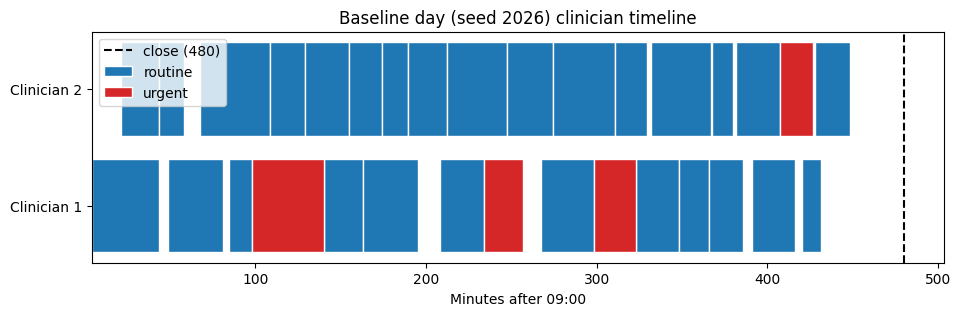

In [8]:
baseline_day = simulate_clinic_day(
    baseline_schedule,
    seed=2026,
    n_clinicians=N_CLINICIANS,
    queue_rule="fcfs",
)

assert (baseline_day["wait_min"] >= 0).all()
assert (baseline_day["service_duration_min"] > 0).all()
print("Visits in this day:", len(baseline_day), "| Scheduled appointments:", len(baseline_schedule))

# Five longest waits
display(baseline_day.nlargest(5, "wait_min")[
    ["visit_id", "urgency", "clinician", "arrival_minute", "service_start_minute", "wait_min"]
].round(1))

# Clinician timeline
fig, ax = plt.subplots(figsize=(11, 3))
for urgency, color in [("routine", "tab:blue"), ("urgent", "tab:red")]:
    d = baseline_day[baseline_day["urgency"] == urgency]
    ax.barh(d["clinician"], d["service_duration_min"], left=d["service_start_minute"],
            color=color, edgecolor="white", label=urgency)
ax.axvline(CLINIC_CLOSE_MINUTE, color="black", ls="--", label="close (480)")
ax.set(yticks=[1, 2], yticklabels=["Clinician 1", "Clinician 2"],
       xlabel="Minutes after 09:00", title="Baseline day (seed 2026) clinician timeline")
ax.legend(loc="upper left")
plt.show()

## Exercise 3: Calculate daily operational metrics

In [9]:
def summarise_day(
    visits,
    n_clinicians=N_CLINICIANS,
    closing_minute=CLINIC_CLOSE_MINUTE,
    urgent_wait_review_min=URGENT_WAIT_REVIEW_MIN,
):
    start, finish, wait = visits["service_start_minute"], visits["completion_minute"], visits["wait_min"]
    busy = (np.minimum(finish, closing_minute) - np.maximum(start, 0)).clip(lower=0).sum()
    urgent = visits[visits["urgency"] == "urgent"]
    return {
        "visits": len(visits),
        "started_by_close": int((start < closing_minute).sum()),
        "mean_wait_min": wait.mean(),
        "median_wait_min": wait.median(),
        "p90_wait_min": wait.quantile(0.90),
        "max_wait_min": wait.max(),
        "utilization_before_close": busy / (n_clinicians * closing_minute),
        "overtime_min": max(0.0, finish.max() - closing_minute),
        "urgent_visits": len(urgent),
        "urgent_wait_breaches": int((urgent["wait_min"] > urgent_wait_review_min).sum()),
    }


baseline_metrics = summarise_day(baseline_day)
if baseline_metrics is None:
    print("Complete summarise_day to see the baseline metrics.")
else:
    display(pd.Series(baseline_metrics, name="baseline_seed_2026").round(2))

visits                      32.00
started_by_close            32.00
mean_wait_min                5.49
median_wait_min              3.03
p90_wait_min                13.66
max_wait_min                23.50
utilization_before_close     0.83
overtime_min                 0.00
urgent_visits                4.00
urgent_wait_breaches         0.00
Name: baseline_seed_2026, dtype: float64

## Exercise 3: Check the metrics

In [10]:
if baseline_metrics is not None:
    required_metrics = {
        "visits", "started_by_close", "mean_wait_min", "median_wait_min",
        "p90_wait_min", "max_wait_min", "utilization_before_close",
        "overtime_min", "urgent_visits", "urgent_wait_breaches",
    }
    assert required_metrics.issubset(baseline_metrics)
    assert 0 <= baseline_metrics["utilization_before_close"] <= 1
    assert baseline_metrics["mean_wait_min"] <= baseline_metrics["max_wait_min"]
    assert baseline_metrics["urgent_wait_breaches"] <= baseline_metrics["urgent_visits"]
    print("Metric checks passed.")
else:
    print("Metric checks skipped until summarise_day is completed.")

Metric checks passed.


## Exercise 4: Define the scheduling policies

In [11]:
policy_definitions = {
    "baseline_fcfs": {
        "schedule": build_schedule(requests),
        "queue_rule": "fcfs",
    },
    "reserve_2_fcfs": {
        "schedule": build_schedule(requests, reserve_slots=2),
        "queue_rule": "fcfs",
    },
    "overbook_2_score_guided": {
        "schedule": build_schedule(
            requests,
            overbook_slots=2,
            score_guided_overbooking=True,
        ),
        "queue_rule": "fcfs",
    },
    "baseline_urgent_priority": {
        "schedule": build_schedule(requests),
        "queue_rule": "urgent_priority",
    },
}

pd.DataFrame(
    [
        {
            "policy": name,
            "scheduled_requests": len(spec["schedule"]),
            "overbooked_requests": (spec["schedule"]["booking_type"] == "overbooked").sum(),
            "queue_rule": spec["queue_rule"],
        }
        for name, spec in policy_definitions.items()
    ]
)

,policy,scheduled_requests,overbooked_requests,queue_rule
0,baseline_fcfs,30,0,fcfs
1,reserve_2_fcfs,28,0,fcfs
2,overbook_2_score_guided,32,2,fcfs
3,baseline_urgent_priority,30,0,urgent_priority


## Exercise 4: Run each policy for 300 days

In [12]:
def evaluate_policy(
    policy_name,
    policy_spec,
    seeds,
    urgent_rate=4.0,
    no_show_logit_shift=0.0,
):
    # Run one policy repeatedly after summarise_day has been implemented.
    rows = []
    for simulation_id, seed in enumerate(seeds):
        visits = simulate_clinic_day(
            policy_spec["schedule"],
            seed=int(seed),
            n_clinicians=N_CLINICIANS,
            queue_rule=policy_spec["queue_rule"],
            urgent_rate=urgent_rate,
            no_show_logit_shift=no_show_logit_shift,
        )
        metrics = summarise_day(visits)
        if metrics is None:
            return None
        rows.append(
            {
                "policy": policy_name,
                "simulation_id": simulation_id,
                "seed": int(seed),
                **metrics,
            }
        )
    return pd.DataFrame(rows)


simulation_seeds = np.arange(20_000, 20_300)

def run_all_policies(**kwargs):
    # Same seeds for every policy -> fair comparison
    return pd.concat(
        [evaluate_policy(name, spec, simulation_seeds, **kwargs) for name, spec in policy_definitions.items()],
        ignore_index=True,
    )


policy_results = run_all_policies()

if policy_results is None:
    print("Complete Exercise 4 to create policy_results.")
else:
    display(policy_results.head())

,policy,simulation_id,seed,visits,started_by_close,mean_wait_min,median_wait_min,p90_wait_min,max_wait_min,utilization_before_close,overtime_min,urgent_visits,urgent_wait_breaches
0,baseline_fcfs,0,20000,29,29,15.469978,11.692476,41.693754,50.725742,0.830711,21.238276,4,0
1,baseline_fcfs,1,20001,32,32,45.474626,48.382525,71.871553,79.630140,0.909293,7.837575,5,3
2,baseline_fcfs,2,20002,34,31,47.884402,52.050501,83.488674,92.687510,0.940117,47.131275,6,4
3,baseline_fcfs,3,20003,34,33,31.546786,34.763482,56.888098,62.448676,0.954530,30.023058,7,2
4,baseline_fcfs,4,20004,30,30,6.392889,1.606919,17.131960,30.184471,0.807960,0.000000,2,0


## Exercise 4: Policy summary table and plots

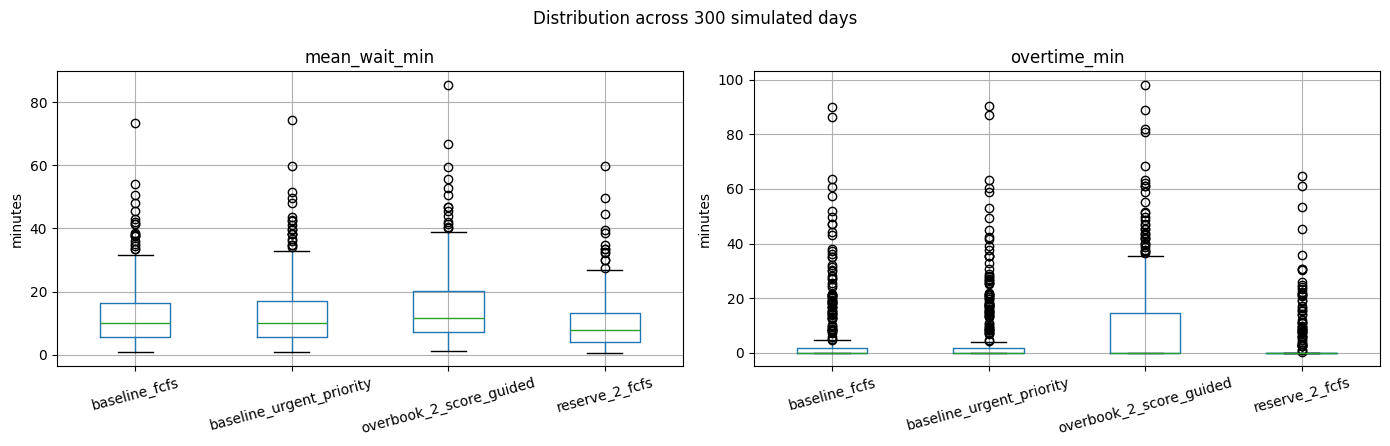

,median_visits,median_started_by_close,median_mean_wait,median_p90_wait,p90_of_p90_wait,median_utilization,p90_overtime,mean_urgent_breaches
policy,,,,,,,,
baseline_fcfs,30.0,30.0,9.98,25.61,53.52,0.82,20.93,0.82
baseline_urgent_priority,30.0,30.0,10.00,26.58,60.48,0.82,21.00,0.05
overbook_2_score_guided,32.0,32.0,11.65,29.03,61.93,0.87,37.13,0.98
reserve_2_fcfs,28.0,28.0,7.77,21.54,46.19,0.78,9.57,0.55


In [13]:
def summarise_policies(results):
    g = results.groupby("policy")
    return pd.DataFrame({
        "median_visits": g["visits"].median(),
        "median_started_by_close": g["started_by_close"].median(),
        "median_mean_wait": g["mean_wait_min"].median(),
        "median_p90_wait": g["p90_wait_min"].median(),
        "p90_of_p90_wait": g["p90_wait_min"].quantile(0.90),
        "median_utilization": g["utilization_before_close"].median(),
        "p90_overtime": g["overtime_min"].quantile(0.90),
        "mean_urgent_breaches": g["urgent_wait_breaches"].mean(),
    }).round(2)


policy_summary = summarise_policies(policy_results)

# Box = typical days, whiskers/dots = high-delay days
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col in zip(axes, ["mean_wait_min", "overtime_min"]):
    policy_results.boxplot(column=col, by="policy", ax=ax, rot=15)
    ax.set(title=col, xlabel="", ylabel="minutes")
plt.suptitle("Distribution across 300 simulated days")
plt.tight_layout()
plt.show()

if policy_summary is None:
    print("Create policy_summary after policy_results is available.")
else:
    display(policy_summary)

## Exercise 5: Stress test (demand surge and attendance drift)

In [14]:
surge_results = run_all_policies(urgent_rate=7.0)
surge_summary = summarise_policies(surge_results)

attendance_drift_results = run_all_policies(no_show_logit_shift=-0.6)
attendance_drift_summary = summarise_policies(attendance_drift_results)

print("Demand-surge summary ready:", surge_summary is not None)
print("Attendance-drift summary ready:", attendance_drift_summary is not None)

print("\nDemand surge (urgent_rate = 7):")
display(surge_summary)
print("Attendance drift (logit shift = -0.6):")
display(attendance_drift_summary)

# Compare the key outcomes across the three scenarios
key = ["median_mean_wait", "p90_of_p90_wait", "p90_overtime", "mean_urgent_breaches"]
display(pd.concat({"normal": policy_summary[key], "surge": surge_summary[key],
                   "drift": attendance_drift_summary[key]}, axis=1))

Demand-surge summary ready: True
Attendance-drift summary ready: True

Demand surge (urgent_rate = 7):


,median_visits,median_started_by_close,median_mean_wait,median_p90_wait,p90_of_p90_wait,median_utilization,p90_overtime,mean_urgent_breaches
policy,,,,,,,,
baseline_fcfs,33.0,32.0,19.61,42.55,86.65,0.90,62.90,2.67
baseline_urgent_priority,33.0,32.0,20.55,50.43,105.62,0.90,60.18,0.20
overbook_2_score_guided,35.0,33.0,23.25,47.74,96.14,0.93,80.92,3.14
reserve_2_fcfs,31.0,31.0,15.30,36.06,74.12,0.86,43.26,2.08


Attendance drift (logit shift = -0.6):


,median_visits,median_started_by_close,median_mean_wait,median_p90_wait,p90_of_p90_wait,median_utilization,p90_overtime,mean_urgent_breaches
policy,,,,,,,,
baseline_fcfs,32.0,32.0,11.62,28.21,61.21,0.86,31.28,0.90
baseline_urgent_priority,32.0,32.0,11.62,29.21,69.23,0.86,30.69,0.06
overbook_2_score_guided,33.0,33.0,15.08,33.37,67.55,0.91,44.01,1.21
reserve_2_fcfs,30.0,30.0,8.83,23.79,49.95,0.81,15.37,0.66


normal                                                              surge  \
                         median_mean_wait p90_of_p90_wait p90_overtime mean_urgent_breaches median_mean_wait   
policy                                                                                                         
baseline_fcfs                        9.98           53.52        20.93                 0.82            19.61   
baseline_urgent_priority            10.00           60.48        21.00                 0.05            20.55   
overbook_2_score_guided             11.65           61.93        37.13                 0.98            23.25   
reserve_2_fcfs                       7.77           46.19         9.57                 0.55            15.30   

                                                                                      drift                  \
                         p90_of_p90_wait p90_overtime mean_urgent_breaches median_mean_wait p90_of_p90_wait   
policy                                                                                                        
baseline_fcfs                      86.65        62.90                 2.67            11.62           61.21   
baseline_urgent_priority          105.62        60.18                 0.20            11.62           69.23   
overbook_2_score_guided            96.14        80.92                 3.14            15.08           67.55   
reserve_2_fcfs                     74.12        43.26                 2.08             8.83           49.95   

                                                            
                         p90_overtime mean_urgent_breaches  
policy                                                      
baseline_fcfs                   31.28                 0.90  
baseline_urgent_priority        30.69                 0.06  
overbook_2_score_guided         44.01                 1.21  
reserve_2_fcfs                  15.37                 0.66

## Exercise 6: Subgroup audit by access group

In [15]:
sg_schedule = policy_definitions["overbook_2_score_guided"]["schedule"]
booking_audit_by_group = pd.crosstab(sg_schedule["access_group"], sg_schedule["booking_type"], margins=True)

# Patients whose slot receives the extra booking (highest predicted no-show)
print("Host patients of the overbooked slots:")
display(baseline_schedule.nlargest(2, "predicted_no_show_probability")[
    ["request_id", "access_group", "travel_minutes", "scheduled_minute", "predicted_no_show_probability"]])


def subgroup_waits(policy):
    spec = policy_definitions[policy]
    days = [simulate_clinic_day(spec["schedule"], seed=int(s), queue_rule=spec["queue_rule"])
            for s in simulation_seeds]
    v = pd.concat(days)
    v = v[v["source"] == "scheduled"]  # drop urgent arrivals (no access_group)
    out = v.groupby("access_group")["wait_min"].agg(
        attended_n="count", mean_wait="mean", p90_wait=lambda w: w.quantile(0.90))
    return out.assign(policy=policy)


subgroup_results = pd.concat(
    [subgroup_waits(p) for p in ["baseline_fcfs", "overbook_2_score_guided"]]
).reset_index().round(2)

if booking_audit_by_group is None:
    print("Create booking_audit_by_group.")
else:
    display(booking_audit_by_group)

if subgroup_results is None:
    print("Create subgroup_results with sample sizes and waiting measures.")
else:
    display(subgroup_results)

Host patients of the overbooked slots:


,request_id,access_group,travel_minutes,scheduled_minute,predicted_no_show_probability
5,R005,far_from_clinic,72,60,0.31995
27,R027,far_from_clinic,72,390,0.31995


booking_type,overbooked,standard,All
access_group,,,
far_from_clinic,0,9,9
near_clinic,2,21,23
All,2,30,32


,access_group,attended_n,mean_wait,p90_wait,policy
0,far_from_clinic,2149,11.20,34.11,baseline_fcfs
1,near_clinic,5710,13.79,39.58,baseline_fcfs
2,far_from_clinic,2118,14.02,41.40,overbook_2_score_guided
3,near_clinic,6252,16.32,45.28,overbook_2_score_guided
